<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

**Worker: [vgi-color](https://github.com/Query-farm/vgi-color)**

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-color/blob/main/notebooks/01_keep_the_color_earn_the_contrast.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-color/blob/main/notebooks/README.md)

# 01 · Keep the color, earn the contrast

**How much must a brand accent change before its label reaches a text-contrast target?**
Our synthetic design brief starts with a tomato-colored card and white text. We
will measure that pair, use the worker's CSS catalog to see why color difference
and text contrast answer different questions, and search for a nearby replacement.
The final decision compares changing the background with changing the label.

**Data: a synthetic design brief and the real worker's CSS named-color catalog.**
All colors are opaque sRGB, with no gradients, transparency or display calibration.
There is no acquisition timestamp or live feed. The local Rust worker performs
every color conversion and measurement through Haybarn / VGI.

We check a numerical contrast condition for ordinary text; this does not certify
an interface's accessibility. CIEDE2000 distance helps rank color similarity and
is not a guarantee of legibility or distinguishability for every viewer.

## Set the design brief

The brand background and label accept exactly six hexadecimal sRGB digits after
`#` (no alpha channel). `MIN_CONTRAST` is a unitless ratio from **1 to 21**; the
saved **4.5:1** target matches the WCAG AA contrast minimum for ordinary text.
**7:1** matches the enhanced AAA contrast threshold. These are text-contrast
thresholds, not complete conformance levels. See the W3C explanations for
[minimum contrast](https://www.w3.org/WAI/WCAG22/Understanding/contrast-minimum.html)
and [enhanced contrast](https://www.w3.org/WAI/WCAG22/Understanding/contrast-enhanced.html).

Edit the visible parameters, then **Restart Kernel → Run All**. The focused end
experiment changes only `MIN_CONTRAST` to `7.0`; all candidate colors remain the same.

In [1]:
BRAND_HEX = "#ff6347"  # opaque sRGB background; exactly #RRGGBB
LABEL_HEX = "#ffffff"  # opaque sRGB foreground; exactly #RRGGBB
MIN_CONTRAST = 4.5      # ratio, inclusive range 1–21; experiment: 7.0

In [2]:
import importlib.metadata as packages
import sys

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.6":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.6"
    if "vgi_notebooks" in sys.modules:
        raise RuntimeError("Restart the session after updating the example tools, then run all.")

In [3]:
from vgi_notebooks import check_runtime, connect, prepare, theme

check_runtime()
prepare("color")
import color_example as example

brand_sql, label_sql = example.validate_parameters(BRAND_HEX, LABEL_HEX, MIN_CONTRAST)
session = connect(globals())
theme()

## Connect to the color engine

The literal `github-auto://Query-farm/vgi-color@v0.5.0` location selects the
published release for your platform. VGI verifies the release checksum, caches
the archive and starts the worker locally; no Rust build or worker checkout is needed. The connection and domain SQL stay visible; Python only configures the
session, draws the returned values and writes result-derived interpretations.

In [4]:
%%sql
FORCE INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'color' (TYPE vgi, LOCATION 'github-auto://Query-farm/vgi-color@v0.5.0');
SELECT extension_name, extension_version, loaded
FROM duckdb_extensions() WHERE extension_name = 'vgi';

,extension_name,extension_version,loaded
0,vgi,e75482339d,True


In [5]:
example.run_note(BRAND_HEX, LABEL_HEX, MIN_CONTRAST)

**Local computational run.** Background `#ff6347`, label `#ffffff`, target **4.5:1**. Worker release **v0.5.0**, verified by the VGI GitHub transport. No external color measurements are fetched.

## Start with the existing pair

Contrast depends on the relative luminances of the label and its background.
The worker linearizes sRGB channels before applying the luminance weights; HSL
lightness is not the luminance used by this formula. We also ask for the better
of black and white text, which gives us a concrete alternative to changing the
brand background. `is_dark` implements that choice using the contrast crossover.

`wcag_level` labels numerical text thresholds: AAA at 7:1, AA at 4.5:1,
AA Large at 3:1, and fail below 3:1. The large-text label does not meet
our ordinary-text brief; none of these labels certifies a whole interface.

In [6]:
%%sql
CREATE OR REPLACE TABLE brief AS
SELECT {{ brand_sql }} AS brand_hex, {{ label_sql }} AS label_hex,
       {{ MIN_CONTRAST }}::DOUBLE AS minimum_contrast;
CREATE OR REPLACE TABLE baseline AS
SELECT *,
       color.main.contrast_ratio(label_hex, brand_hex) AS contrast_ratio,
       color.main.delta_e(label_hex, brand_hex) AS pair_delta_e,
       color.main.luminance(brand_hex) AS background_luminance,
       color.main.wcag_level(label_hex, brand_hex) AS worker_text_grade,
       CASE WHEN color.main.is_dark(brand_hex) THEN '#ffffff' ELSE '#000000' END AS alternate_label
FROM brief;


,Count


In [7]:
%%sql baseline_frame <<
SELECT * FROM baseline;

In [8]:
example.baseline_finding(baseline_frame, MIN_CONTRAST)

,brand_hex,label_hex,minimum_contrast,contrast_ratio,pair_delta_e,background_luminance,worker_text_grade,alternate_label
0,#ff6347,#ffffff,4.5,2.946243,38.027654,0.306386,fail,#000000


The original pair **misses the 4.5:1 target** at **2.9462:1**. Its label/background distance is **ΔE₀₀ 38.03**. That second number does not determine whether the text-contrast condition passes. All eligibility comparisons below use unrounded ratios; displayed digits are for inspection.

The background relative luminance is **0.3064** on a 0–1 scale. The worker returns text grade **fail** for the original pair, independently of our custom target. Its black/white crossover chooses **`#000000`** text; the decision cards below measure that alternative.

## Does a larger color difference mean stronger text contrast?

Hold the label fixed and measure every distinct CSS background returned by the
worker. Different CSS keywords can name the same hex color; we group those
aliases so repeated colors do not get extra weight. The table also checks for
missing measurements before any ranking.

Here **pair ΔE₀₀** compares the label with each background. It is the
[CIEDE2000 color-difference formula](https://hajim.rochester.edu/ece/sites/gsharma/ciede2000/)
applied to the worker's D65 CIELAB conversions. We do not impose a universal
“noticeable difference” cutoff or simulate color-vision deficiencies.

In [9]:
%%sql
CREATE OR REPLACE TABLE css_names AS SELECT * FROM color.main.named_colors();
CREATE OR REPLACE TABLE css_pairs AS
SELECT n.*, b.label_hex, b.minimum_contrast,
       color.main.contrast_ratio(b.label_hex, n.hex) AS contrast_ratio,
       color.main.delta_e(b.label_hex, n.hex) AS pair_delta_e
FROM (SELECT MIN(name) AS name, hex, COUNT(*) AS aliases FROM css_names GROUP BY hex) n
CROSS JOIN brief b;
SELECT (SELECT COUNT(*) FROM css_names) AS css_keywords,
       COUNT(*) AS distinct_backgrounds,
       SUM(aliases - 1) AS duplicate_spellings,
       COUNT(*) FILTER (WHERE contrast_ratio IS NULL OR pair_delta_e IS NULL) AS missing_measurements,
       COUNT(*) FILTER (WHERE contrast_ratio >= minimum_contrast) AS backgrounds_meeting_target
FROM css_pairs;

,css_keywords,distinct_backgrounds,duplicate_spellings,missing_measurements,backgrounds_meeting_target
0,148,139,9.0,0,30


In [10]:
%%sql css_frame <<
SELECT * FROM css_pairs ORDER BY name;

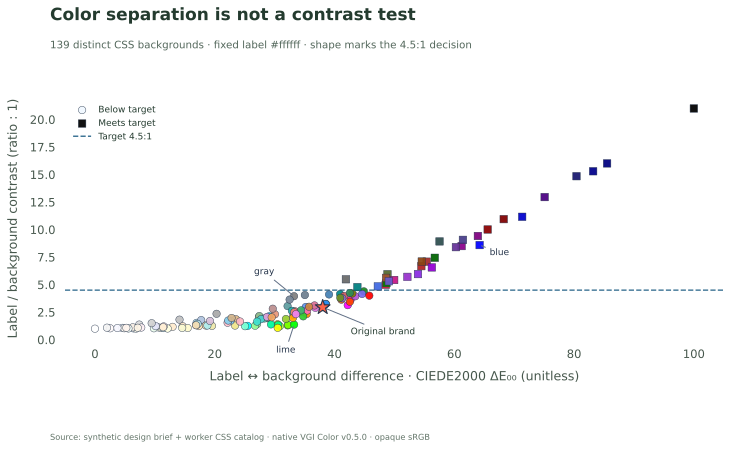

In [11]:
example.css_chart(css_frame, baseline_frame, BRAND_HEX, LABEL_HEX, MIN_CONTRAST)

In [12]:
%%sql inversion <<
SELECT a.name AS larger_distance_color, a.hex AS larger_distance_hex,
       a.pair_delta_e AS larger_distance, a.contrast_ratio AS lower_contrast,
       b.name AS smaller_distance_color, b.hex AS smaller_distance_hex,
       b.pair_delta_e AS smaller_distance, b.contrast_ratio AS higher_contrast
FROM css_pairs a JOIN css_pairs b ON a.pair_delta_e > b.pair_delta_e
                               AND a.contrast_ratio < b.contrast_ratio
ORDER BY b.contrast_ratio - a.contrast_ratio DESC, a.name, b.name
LIMIT 1;

In [13]:
example.inversion_finding(inversion)

A concrete reversal: **lime** is farther from the label (ΔE₀₀ 33.26) yet has only **1.37:1** contrast. **gray** is closer (ΔE₀₀ 33.24) but yields **3.95:1**. Ranking by color difference would therefore answer a different question. Next we constrain contrast first, then minimize departure from the brand.

## Search one controlled family of backgrounds

Keep the brand's HSL hue and saturation fixed; evaluate lightness from **0.00 to
1.00 inclusive in steps of 0.01**, plus the original color. The worker rounds the
result to 8-bit sRGB, so the plotted path is a finite candidate grid, not an exact
continuous optimum. Equal HSL steps do not imply equal perceptual steps.

Here the distance reference changes: **brand ΔE₀₀** compares each candidate
background with the **original background**, not with the text. Filter for the
contrast target, then choose the least brand distance. Ties favor higher contrast,
then hexadecimal order. We retain the original as a candidate so a design that
already meets the target need not change at all.

In [14]:
%%sql
CREATE OR REPLACE TABLE brand_space AS
SELECT brand_hex,rgb,color.main.rgb_to_hsl(rgb.r, rgb.g, rgb.b) AS hsl
FROM (SELECT brand_hex,color.main.from_hex(brand_hex) AS rgb FROM brief);


,Count


In [15]:
%%sql space_frame <<
SELECT brand_hex,rgb.r AS r,rgb.g AS g,rgb.b AS b,
       hsl.h AS h,hsl.s AS s,hsl.l AS l
FROM brand_space;

In [16]:
example.space_finding(space_frame)

,brand_hex,r,g,b,h,s,l
0,#ff6347,255,99,71,9.130435,1.0,0.639216


Hex **`#ff6347`** becomes RGB **(255,99,71)** and HSL **(9.13°, 1.0000, 0.6392)**. The family holds the first two HSL coordinates fixed. HSL lightness is a construction coordinate, while relative luminance weights linearized RGB channels; they are not interchangeable.

In [17]:
%%sql
CREATE OR REPLACE TABLE shade_grid AS
WITH rgb_grid AS (
    SELECT k / 100.0 AS lightness,
           color.main.hsl_to_rgb(hsl.h, hsl.s, k / 100.0) AS rgb
    FROM brand_space CROSS JOIN range(0, 101) t(k)
)
SELECT lightness, color.main.to_hex(rgb.r, rgb.g, rgb.b) AS hex FROM rgb_grid;
CREATE OR REPLACE TABLE candidates AS
WITH unique_colors AS (
    SELECT hex, MIN(lightness) AS lightness FROM (
        SELECT * FROM shade_grid
        UNION ALL
        SELECT hsl.l, brand_hex FROM brand_space
    ) GROUP BY hex
)
SELECT c.*, b.label_hex, b.brand_hex, b.minimum_contrast,
       color.main.contrast_ratio(b.label_hex, c.hex) AS contrast_ratio,
       color.main.delta_e(b.brand_hex, c.hex) AS brand_delta_e
FROM unique_colors c CROSS JOIN brief b;
CREATE OR REPLACE TABLE chosen AS
SELECT * FROM candidates
WHERE contrast_ratio >= minimum_contrast
ORDER BY brand_delta_e, contrast_ratio DESC, hex
LIMIT 1;
SELECT COUNT(*) AS distinct_candidates,
       COUNT(*) FILTER (WHERE contrast_ratio >= minimum_contrast) AS eligible_candidates,
       COUNT(*) FILTER (WHERE contrast_ratio IS NULL OR brand_delta_e IS NULL) AS missing_measurements,
       (SELECT hex FROM chosen) AS selected_background,
       (SELECT ROUND(contrast_ratio, 4) FROM chosen) AS selected_contrast,
       (SELECT ROUND(brand_delta_e, 2) FROM chosen) AS selected_brand_delta_e
FROM candidates;

,distinct_candidates,eligible_candidates,missing_measurements,selected_background,selected_contrast,selected_brand_delta_e
0,101,46,0,#e52300,4.5932,12.95


In [18]:
%%sql candidate_frame <<
SELECT c.*, EXISTS (SELECT 1 FROM chosen s WHERE s.hex = c.hex) AS selected
FROM candidates c ORDER BY lightness, hex;

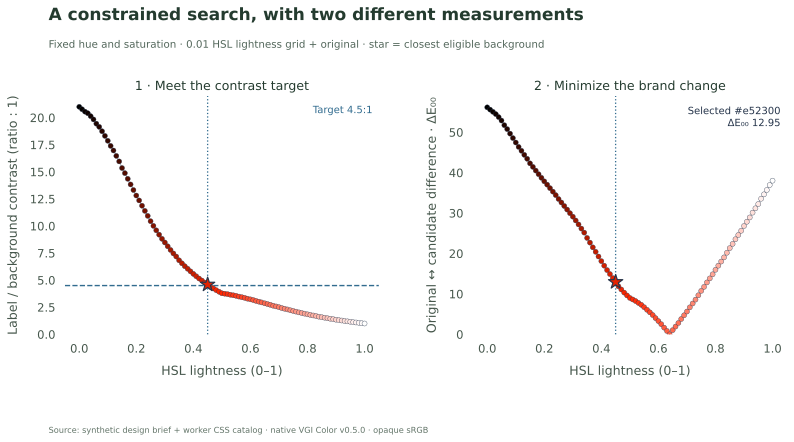

**46 of 101 candidates meet 4.5:1.** The closest eligible background is **`#e52300`** at **4.5932:1**, with brand distance **ΔE₀₀ 12.95** and HSL lightness **0.450**. This is the optimum within the sampled family only: allowing hue or saturation to change, or refining the grid, could produce a different answer.

In [19]:
example.shade_chart(candidate_frame, MIN_CONTRAST, LABEL_HEX)

## Choose what the design is allowed to change

A smaller background adjustment is useful only if the label must stay fixed.
If the background is the stronger brand constraint, changing the label may be
cheaper. Compare the original pair, the selected background (when one exists),
and the better of black or white labels on the original background.

The card previews show these exact opaque sRGB pairs. Their printed ratios, not
the appearance of your screen or the preview's font size, drive the decision.

In [20]:
%%sql
CREATE OR REPLACE TABLE decisions AS
SELECT 1 AS ordering, 'Original pair' AS option, brand_hex AS background,
       label_hex AS foreground, contrast_ratio, 0.0 AS background_delta_e,
       contrast_ratio >= minimum_contrast AS meets_target
FROM baseline
UNION ALL
SELECT 2, 'Adjust background', hex, label_hex, contrast_ratio, brand_delta_e,
       contrast_ratio >= minimum_contrast FROM chosen
UNION ALL
SELECT 3, 'Use black / white label', brand_hex, alternate_label,
       color.main.contrast_ratio(alternate_label, brand_hex), 0.0,
       color.main.contrast_ratio(alternate_label, brand_hex) >= minimum_contrast
FROM baseline;
SELECT option, background, foreground, ROUND(contrast_ratio, 4) AS contrast_ratio,
       ROUND(background_delta_e, 2) AS background_delta_e, meets_target
FROM decisions ORDER BY ordering;

,option,background,foreground,contrast_ratio,background_delta_e,meets_target
0,Original pair,#ff6347,#ffffff,2.9462,0.00,False
1,Adjust background,#e52300,#ffffff,4.5932,12.95,True
2,Use black / white label,#ff6347,#000000,7.1277,0.00,True


In [21]:
%%sql decision_frame <<
SELECT * FROM decisions ORDER BY ordering;

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


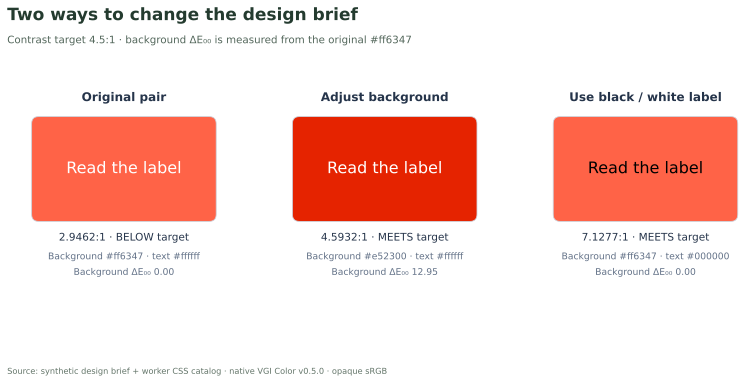

Keeping `#ff6347` and using **`#000000`** text gives **7.1277:1**, which **meets** the current target. Its background ΔE₀₀ is zero because the background is unchanged; the label itself may change substantially. The choice depends on which part of the design brief can move. Neither metric evaluates text size, focus states, color-only meaning, typography, or the whole user experience.

In [22]:
example.decision_chart(decision_frame, MIN_CONTRAST, BRAND_HEX)

## Verify relationships, not a favorite color

These checks stay meaningful when you change the brief: ratios stay within their
physical range, color differences are symmetric, the luminance formula agrees
with the worker's contrast result, and the selected row is the closest eligible
candidate. An empty eligible set remains a valid outcome. Missing results are
never replaced with zeros.

In [23]:
%%sql validation <<
SELECT
    (SELECT COUNT(*) = 0 FROM candidates WHERE contrast_ratio IS NULL OR brand_delta_e IS NULL) AS complete_grid,
    (SELECT BOOL_AND(contrast_ratio BETWEEN 1 AND 21 AND brand_delta_e >= 0) FROM candidates) AS metric_bounds,
    (SELECT COUNT(*) = COUNT(DISTINCT hex) FROM candidates) AS unique_candidates,
    (SELECT BOOL_AND(ABS(brand_delta_e - color.main.delta_e(hex, brand_hex)) < 1e-9) FROM candidates) AS delta_e_symmetry,
    (SELECT BOOL_AND(ABS(contrast_ratio -
       (GREATEST(color.main.luminance(label_hex), color.main.luminance(hex)) + 0.05) /
       (LEAST(color.main.luminance(label_hex), color.main.luminance(hex)) + 0.05)) < 1e-10)
       FROM candidates) AS luminance_agreement,
    (SELECT COUNT(*) FROM chosen) =
       CASE WHEN EXISTS (SELECT 1 FROM candidates WHERE contrast_ratio >= minimum_contrast) THEN 1 ELSE 0 END AS selection_coverage,
    NOT EXISTS (SELECT 1 FROM chosen s JOIN candidates c ON c.contrast_ratio >= c.minimum_contrast
                AND c.brand_delta_e < s.brand_delta_e - 1e-10) AS closest_eligible,
    (SELECT BOOL_AND(contrast_ratio IS NOT NULL AND pair_delta_e IS NOT NULL) FROM css_pairs) AS complete_css,
    color.main.contrast_ratio('invalid', '#ffffff') IS NULL AS invalid_stays_null;

In [24]:
example.check_results(validation)

,passed
complete_grid,True
metric_bounds,True
unique_candidates,True
delta_e_symmetry,True
luminance_agreement,True
selection_coverage,True
closest_eligible,True
complete_css,True
invalid_stays_null,True


**All 9 relationship checks passed.** Eligibility uses the full returned contrast ratio, including near a threshold; chart labels and tables alone are rounded.

## Focused experiment: ask for 7:1

Change only **`MIN_CONTRAST = 7.0`**, then restart and run all. Before running,
predict what happens: the candidate colors and their measurements should stay
identical, while the eligible set can only shrink. The minimum achievable brand
distance among eligible candidates cannot improve when the constraint tightens.
For the default white label, expect the chosen tomato-family background to darken.

Compare the eligible count, selected hex, selected contrast and brand ΔE₀₀ in the
search summary, then inspect the three decision cards. Does the black/white label
alternative still meet the stronger target without changing the background?
If a chosen row disappears, that means this sampled family cannot satisfy the
new target with the fixed label; it does not justify selecting a failing row.

This experiment changes a design requirement, not human perception or the color
science model. Passing 7:1 alone does not establish complete WCAG AAA conformance.
Reset **`MIN_CONTRAST = 4.5`** for the saved default.
[Save the experiment separately](README.md#one-parameter-experiment) with the runner.

In [25]:
con.execute("DETACH color")
session.close()

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-color](https://github.com/Query-farm/vgi-color)
